In [1]:

# ============================================================
# PRE 15 - ESTRUCTURA GRÁFICA DE ACCIONES BURSÁTILES
# Manu | Carga de datos históricos (2003 - 2008)
# ============================================================

import glob
import pandas as pd
from pathlib import Path

# ============================================================
# 1. IDENTIFICACIÓN DE ARCHIVOS
# ============================================================

# Manu: Localizar los archivos históricos comprimidos
files = sorted(glob.glob("../data/*.csv.zip"))

# Manu: Comprobar que existen archivos para el análisis
if not files:
    raise FileNotFoundError(
        "No se encontraron archivos CSV comprimidos "
        "en la carpeta ../data/"
    )

# ============================================================
# 2. CARGA DE DATOS
# ============================================================

# Manu: Almacenar las cotizaciones históricas
quotes = []

for file in files:

    # Manu: Leer cada archivo comprimido
    cotizaciones = pd.read_csv(
        file,
        compression="zip"
    )

    # Manu: Validar las columnas utilizadas en el laboratorio
    columnas_necesarias = {"open", "close"}

    if not columnas_necesarias.issubset(cotizaciones.columns):
        raise ValueError(
            f"Faltan columnas open/close en: {file}"
        )

    quotes.append(cotizaciones)

# ============================================================
# 3. VERIFICACIÓN INICIAL
# ============================================================

print("Archivos cargados correctamente:", len(quotes))
print("Observaciones del primer archivo:", len(quotes[0]))
print("Primeros archivos encontrados:")

for file in files[:5]:
    print("-", Path(file).name)

print("PASSED - Carga inicial de datos completada")


Archivos cargados correctamente: 56
Observaciones del primer archivo: 1258
Primeros archivos encontrados:
- AAPL.csv.zip
- AIG.csv.zip
- AMZN.csv.zip
- AXP.csv.zip
- BA.csv.zip
PASSED - Carga inicial de datos completada


In [2]:
#
# Calculo de las variaciones diarias
#
import numpy as np  # type: ignore

close_prices = np.vstack([q["close"] for q in quotes])
open_prices = np.vstack([q["open"] for q in quotes])
variation = close_prices - open_prices

In [3]:

# ============================================================
# PRE 15 - APRENDIZAJE DE LA ESTRUCTURA GRÁFICA
# Manu | Estimación de dependencias entre acciones
# ============================================================

import numpy as np
from sklearn import covariance

# ============================================================
# 1. VERIFICACIÓN DE DATOS
# ============================================================

# Manu: Verificar que ya se calcularon las variaciones
if "variation" not in globals():
    raise NameError(
        "Primero debes ejecutar la celda que calcula variation."
    )

# ============================================================
# 2. PREPARACIÓN DE LOS DATOS
# ============================================================

# Manu: Organizar las observaciones por filas y acciones por columnas
X = np.asarray(variation, dtype=float).copy().T

# Manu: Calcular la desviación estándar de cada acción
desviaciones = X.std(axis=0)

# Manu: Evitar divisiones inválidas durante la normalización
if not np.isfinite(X).all():
    raise ValueError("Los datos contienen valores no finitos.")

if np.any(desviaciones == 0):
    raise ValueError(
        "Existen acciones con desviación estándar igual a cero."
    )

# Manu: Estandarizar las variaciones de cada acción
X /= desviaciones

# ============================================================
# 3. APRENDIZAJE DE LA ESTRUCTURA GRÁFICA
# ============================================================

# Manu: Mantener el rango de regularización del profesor
alphas = np.logspace(-1.5, 1, num=10)

# Manu: Configurar Graphical Lasso con validación cruzada
edge_model = covariance.GraphicalLassoCV(
    alphas=alphas
)

# Manu: Ajustar el modelo a los datos estandarizados
edge_model.fit(X)

# ============================================================
# 4. VERIFICACIÓN DE RESULTADOS
# ============================================================

print("Modelo ajustado correctamente")
print("Número de acciones:", X.shape[1])
print("Número de observaciones:", X.shape[0])
print("Alpha seleccionado:", edge_model.alpha_)

assert edge_model.covariance_.shape == (
    X.shape[1], X.shape[1]
)

print("PASSED - Estructura gráfica estimada correctamente")


Modelo ajustado correctamente
Número de acciones: 56
Número de observaciones: 1258
Alpha seleccionado: 0.05994842503189409
PASSED - Estructura gráfica estimada correctamente


In [4]:
#
# Nombres de las acciones
#
symbol_dict = {
    "TOT": "Total",
    "XOM": "Exxon",
    "CVX": "Chevron",
    "COP": "ConocoPhillips",
    "VLO": "Valero Energy",
    "MSFT": "Microsoft",
    "IBM": "IBM",
    "TWX": "Time Warner",
    "CMCSA": "Comcast",
    "CVC": "Cablevision",
    "YHOO": "Yahoo",
    "DELL": "Dell",
    "HPQ": "HP",
    "AMZN": "Amazon",
    "TM": "Toyota",
    "CAJ": "Canon",
    "SNE": "Sony",
    "F": "Ford",
    "HMC": "Honda",
    "NAV": "Navistar",
    "NOC": "Northrop Grumman",
    "BA": "Boeing",
    "KO": "Coca Cola",
    "MMM": "3M",
    "MCD": "McDonald's",
    "PEP": "Pepsi",
    "K": "Kellogg",
    "UN": "Unilever",
    "MAR": "Marriott",
    "PG": "Procter Gamble",
    "CL": "Colgate-Palmolive",
    "GE": "General Electrics",
    "WFC": "Wells Fargo",
    "JPM": "JPMorgan Chase",
    "AIG": "AIG",
    "AXP": "American express",
    "BAC": "Bank of America",
    "GS": "Goldman Sachs",
    "AAPL": "Apple",
    "SAP": "SAP",
    "CSCO": "Cisco",
    "TXN": "Texas Instruments",
    "XRX": "Xerox",
    "WMT": "Wal-Mart",
    "HD": "Home Depot",
    "GSK": "GlaxoSmithKline",
    "PFE": "Pfizer",
    "SNY": "Sanofi-Aventis",
    "NVS": "Novartis",
    "KMB": "Kimberly-Clark",
    "R": "Ryder",
    "GD": "General Dynamics",
    "RTN": "Raytheon",
    "CVS": "CVS",
    "CAT": "Caterpillar",
    "DD": "DuPont de Nemours",
}

symbols, names = np.array(sorted(symbol_dict.items())).T

In [5]:
# Clustering

from sklearn import cluster

_, labels = cluster.affinity_propagation(edge_model.covariance_, random_state=0)
n_labels = labels.max()

for i in range(n_labels + 1):
    print(f"Cluster {i + 1}: {', '.join(names[labels == i])}")

Cluster 1: Apple, Amazon, Yahoo
Cluster 2: Comcast, Cablevision, Time Warner
Cluster 3: ConocoPhillips, Chevron, Total, Valero Energy, Exxon
Cluster 4: Cisco, Dell, HP, IBM, Microsoft, SAP, Texas Instruments
Cluster 5: Boeing, General Dynamics, Northrop Grumman, Raytheon
Cluster 6: AIG, American express, Bank of America, Caterpillar, CVS, DuPont de Nemours, Ford, General Electrics, Goldman Sachs, Home Depot, JPMorgan Chase, Marriott, McDonald's, 3M, Ryder, Wells Fargo, Wal-Mart
Cluster 7: GlaxoSmithKline, Novartis, Pfizer, Sanofi-Aventis, Unilever
Cluster 8: Kellogg, Coca Cola, Pepsi
Cluster 9: Colgate-Palmolive, Kimberly-Clark, Procter Gamble
Cluster 10: Canon, Honda, Navistar, Sony, Toyota, Xerox


In [8]:
# Construccion del embedding

from sklearn import manifold

# Busca la mejor posición de los nodos en un espacio 2D
node_position_model = manifold.LocallyLinearEmbedding(
    n_components=2,
    eigen_solver="dense",
    n_neighbors=6,
)

embedding = node_position_model.fit_transform(X.T).T

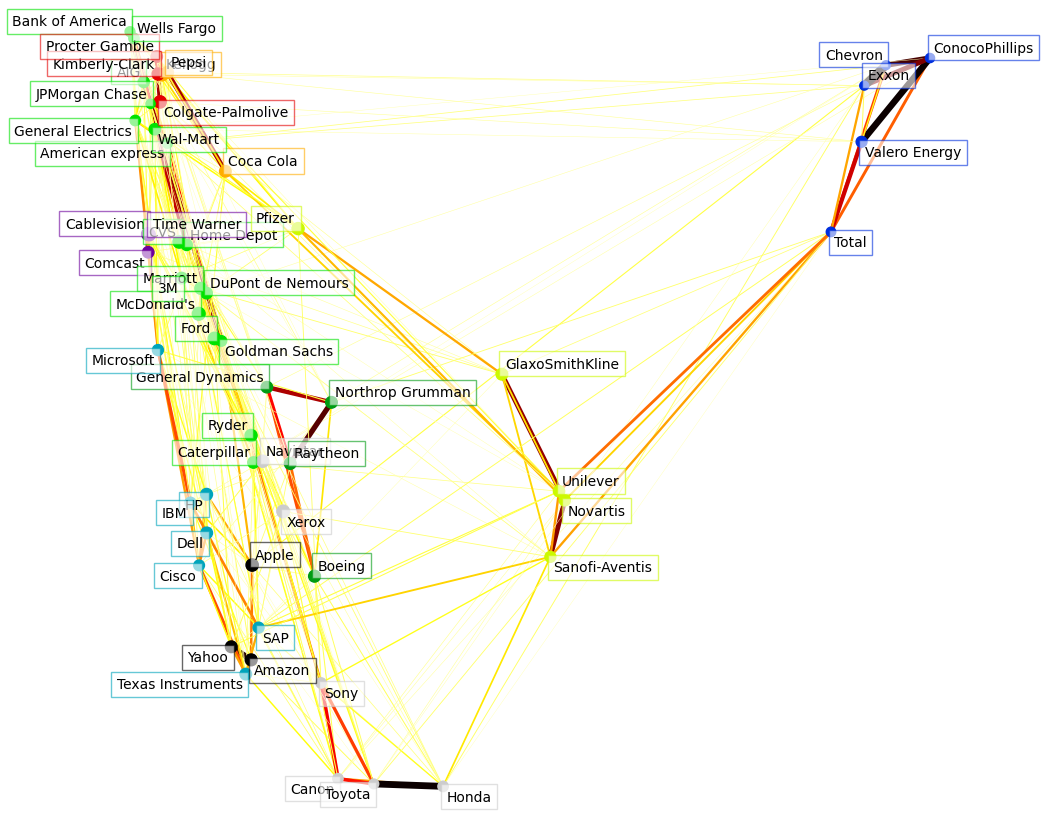

In [9]:
# Visualización

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

plt.figure(1, facecolor="w", figsize=(10, 8))

plt.clf()
ax = plt.axes([0.0, 0.0, 1.0, 1.0])
plt.axis("off")

# Muestra la grafica de las correlaciones parciales
partial_correlations = edge_model.precision_.copy()
d = 1 / np.sqrt(np.diag(partial_correlations))
partial_correlations *= d
partial_correlations *= d[:, np.newaxis]
non_zero = np.abs(np.triu(partial_correlations, k=1)) > 0.02

# Grafica los nodos usando las coordenadas del embedding
plt.scatter(
    embedding[0], embedding[1], s=100 * d**2, c=labels, cmap=plt.cm.nipy_spectral
)

# Grafica los bordes
start_idx, end_idx = np.where(non_zero)
# a sequence of (*line0*, *line1*, *line2*), where::
#            linen = (x0, y0), (x1, y1), ... (xm, ym)
segments = [
    [embedding[:, start], embedding[:, stop]] for start, stop in zip(start_idx, end_idx)
]
values = np.abs(partial_correlations[non_zero])
lc = LineCollection(
    segments, zorder=0, cmap=plt.cm.hot_r, norm=plt.Normalize(0, 0.7 * values.max())
)
lc.set_array(values)
lc.set_linewidths(15 * values)
ax.add_collection(lc)

# Adicional a etiqueta a cada nodo. El reto es posicionar las etiquetas
# para evitar que se traslapen con otras etiquetas
for index, (name, label, (x, y)) in enumerate(zip(names, labels, embedding.T)):
    dx = x - embedding[0]
    dx[index] = 1
    dy = y - embedding[1]
    dy[index] = 1
    this_dx = dx[np.argmin(np.abs(dy))]
    this_dy = dy[np.argmin(np.abs(dx))]
    if this_dx > 0:
        horizontalalignment = "left"
        x = x + 0.002
    else:
        horizontalalignment = "right"
        x = x - 0.002
    if this_dy > 0:
        verticalalignment = "bottom"
        y = y + 0.002
    else:
        verticalalignment = "top"
        y = y - 0.002
    plt.text(
        x,
        y,
        name,
        size=10,
        horizontalalignment=horizontalalignment,
        verticalalignment=verticalalignment,
        bbox=dict(
            facecolor="w",
            edgecolor=plt.cm.nipy_spectral(label / float(n_labels)),
            alpha=0.6,
        ),
    )

plt.xlim(
    embedding[0].min() - 0.15 * np.ptp(embedding[0]),
    embedding[0].max() + 0.10 * np.ptp(embedding[0]),
)
plt.ylim(
    embedding[1].min() - 0.03 * np.ptp(embedding[1]),
    embedding[1].max() + 0.03 * np.ptp(embedding[1]),
)

plt.show()

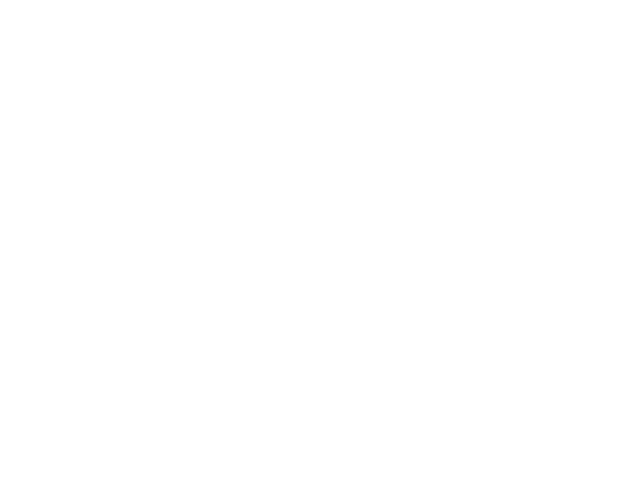

PASSED - stocks.png generado correctamente
Ubicación: ../submission/stocks.png


In [11]:

# ============================================================
# PRE 15 - ESTRUCTURA GRÁFICA DEL MERCADO BURSÁTIL
# Manu | Exportación final de la visualización
# ============================================================

from pathlib import Path
from IPython.display import Image, display

# Manu: Definir la ubicación del archivo solicitado
ruta_imagen = Path("../submission/stocks.png")

# Manu: Verificar que la gráfica se guardó en la celda anterior
assert ruta_imagen.is_file(), (
    "No se encontró stocks.png. "
    "Ejecuta primero la celda de visualización."
)

assert ruta_imagen.stat().st_size > 0, (
    "El archivo stocks.png está vacío."
)

# Manu: Mostrar el resultado final
display(Image(filename=str(ruta_imagen)))

print("PASSED - stocks.png generado correctamente")
print("Ubicación:", ruta_imagen)
